# (3) Example_MNIST_CNN_InMemoryComputing

Questo notebook contiene un esempio su come valutare l'impatto in accuratezza nell'eseguire con In-Memory Computing una Convolutional Neural Network (CNN) già allenata, e su come recuperare l'accuratezza persa con l'_Hardware-Aware Training_.

Tra i tanti simulatori possibili, questo notebook utilizza il framework [**Cross-Sim**](https://github.com/sandialabs/cross-sim). Il codice sorgente di **Cross-Sim** è qui incluso per semplicità nelle cartelle `./applications` e `./simulator`. Per eseguire questo notebook non è richiesta alcuna conoscenza del framework. Nel caso si voglia approfondire le funzionalità di **Cross-Sim** si consiglia di fare riferimento al _git_ specifico del simulatore ed alla sua documentazione.

Il notebook mette a confronto **tutte le reti** create nei notebook precedenti:

| Rete | Allenata nel | File dei pesi |
|---|---|---|
| CNN classica (MNIST) | notebook (1) | `trained_mnist_cnn.pt` |
| CNN con dropout (MNIST) | notebook (1) | `trained_mnist_cnn_dropout.pt` |
| CNN classica (MNIST + personale) | notebook (2) | `trained_mnist_cnn_personale.pt` |
| CNN con dropout (MNIST + personale) | notebook (2) | `trained_mnist_cnn_dropout_personale.pt` |

Percorso del notebook:
1. **sezione 5**: le 4 reti digitali, cioè eseguite su CPU senza errori (accuratezza e robustezza);
2. **sezioni 6 e 7**: le stesse reti eseguite su In-Memory Computing (IMC) simulato con **Cross-Sim**: gli errori delle RRAM fanno calare l'accuratezza;
3. **sezioni 7.1 e 7.2 (provvisorie)**: passaggio intermedio, lavagna e robustezza delle reti IMC prima della correzione;
4. **sezione 8**: _Hardware-Aware Training_ (HAT), le reti vengono riallenate con gli errori dell'IMC dentro il ciclo di training;
5. **sezioni 9 e 10**: accuratezza e robustezza delle reti dopo l'HAT;
6. **sezione 11**: lavagna con le reti digitali e le reti IMC dopo l'HAT; **sezione 12**: tabelle e grafici riassuntivi.

Nelle sezioni 8, 9, 10 e 12 i risultati sono mostrati anche con dei grafici, salvati nella cartella `grafici`.

## 1. Setup and Imports

Importiamo le librerie che ci serviranno.

In [1]:
# Librerie standard
import math
import os

# Calcolo numerico, grafici e reti neurali
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F
from torchvision import datasets, transforms
from tqdm import tqdm

# Cross-Sim: parametri del sistema IMC, modello del dispositivo e conversione delle reti PyTorch
from applications.mvm_params import set_params
from simulator.devices import idevice
from simulator.algorithms.dnn.torch.convert import from_torch, reinitialize, synchronize

# Lavagne interattive (file lavagna.py): raccolta dei disegni di verifica (sezione 2.1) e confronto delle reti (sezioni 7.1 e 11)
from lavagna import apri_lavagna, raccogli_cifre

# Seed fissi: numpy per gli errori di programmazione simulati da Cross-Sim, torch per la suddivisione del dataset.
# Con lo stesso seed del notebook (1) la suddivisione training/validation della sezione 2 è identica a quella del notebook (1).
np.random.seed(42)
_ = torch.manual_seed(42)

## 2. Data Preparation

Come per l'allenamento, è necessario avere accesso al dataset (e.g. MNIST) per fornirlo in ingresso alla rete. Serve anche il training set, perché nella sezione 8 le reti vengono riallenate.

In [2]:
# Inference batch size
batch_size = 64

# Load the MNIST training set
mnist_data = datasets.MNIST("./", download=True, train=True,
                              transform=transforms.Compose([
                                transforms.ToTensor(),
                                transforms.Normalize((0.1307,), (0.3081,))
                                ]),
                              target_transform=transforms.Compose([
                                lambda x:torch.tensor([x]),
                                lambda x:F.one_hot(x,10).float(),
                                lambda x:x.squeeze(),
                                ]))

# Load the MNIST test set
mnist_test = datasets.MNIST("./", download=True, train=False,
                              transform=transforms.Compose([
                                transforms.ToTensor(),
                                transforms.Normalize((0.1307,), (0.3081,))
                                ]),
                              target_transform=transforms.Compose([
                                lambda x:torch.tensor([x]),
                                lambda x:F.one_hot(x,10).float(),
                                lambda x:x.squeeze(),
                                ]))

# Split dataset into training and validation and create data loaders
# (stesso seed del notebook 1: le immagini di validazione non sono mai state usate per allenare le reti)
ds_train, ds_val = torch.utils.data.random_split(mnist_data, [0.8, 0.2])
mnist_loader_train = torch.utils.data.DataLoader(ds_train, batch_size=batch_size, shuffle=True)
mnist_loader_val = torch.utils.data.DataLoader(ds_val, batch_size=batch_size, shuffle=False)

# Create test set loader
mnist_loader_test = torch.utils.data.DataLoader(mnist_test, batch_size=batch_size, shuffle=False)
N_test = len(mnist_loader_test.dataset)

### 2.1 Disegni per la verifica sulla lavagna

Oltre che sul test set MNIST, la robustezza delle reti viene verificata su cifre disegnate a mano sulla lavagna (sezioni 5.1, 7.2 e 10): ogni cifra viene disegnata **4 volte** e tutte le reti classificano gli stessi disegni. A differenza del dataset personale del notebook (4), questi disegni servono solo a verificare le reti e non vengono mai usati per allenarle.

Eseguendo la cella si apre la lavagna di raccolta del notebook (4): in alto è indicata la cifra da disegnare e la lavagna resta sulla stessa cifra finché non ne hai salvati 4 disegni, poi passa alla successiva. Si usa come nel notebook (4): **Salva** (o Invio), **Pulisci**, **Annulla** e **Fine**.

Alla chiusura i disegni vengono salvati nel file `robustezza_lavagna.pt`, che sostituisce quello precedente. Se si chiude la lavagna senza disegnare nulla, resta il file precedente: così, se le cifre sono già state disegnate in un'esecuzione precedente, basta premere **Fine** per riusarle.

Come in tutte le lavagne, il disegno viene solo rimpicciolito a 28x28, senza adattarlo a MNIST. La cella resta in esecuzione finché la finestra è aperta.

In [ ]:
# Lavagna di raccolta del notebook 4 (file lavagna.py): 4 disegni per cifra.
img_lavagna, lab_lavagna, orig_lavagna = raccogli_cifre(campioni_per_cifra=4, titolo='Verifica robustezza sulla lavagna')

# Salvataggio dei disegni (immagini 28x28, etichette e disegni originali 400x400).
if len(lab_lavagna) == 0:
    print('Nessun disegno raccolto: resta il file robustezza_lavagna.pt precedente (se esiste).')
else:
    torch.save({'images': torch.from_numpy(img_lavagna),
                'labels': torch.from_numpy(lab_lavagna),
                'originali': torch.from_numpy(orig_lavagna)}, 'robustezza_lavagna.pt')
    print('Salvati {} disegni in robustezza_lavagna.pt'.format(len(lab_lavagna)))

In [4]:
# Caricamento dei disegni di verifica, preparati come le immagini del DataLoader MNIST:
# cambia solo la scala dei pixel (valori 0-1 e normalizzazione), il disegno non viene adattato a MNIST.
if not os.path.exists('robustezza_lavagna.pt'):
    raise FileNotFoundError('File robustezza_lavagna.pt non trovato: esegui la cella precedente e disegna le cifre.')
dati_lavagna = torch.load('robustezza_lavagna.pt')
x_lavagna = dati_lavagna['images'].float().unsqueeze(1) / 255.0   # (N, 1, 28, 28), valori 0-1
x_lavagna = (x_lavagna - 0.1307) / 0.3081                          # stessa normalizzazione di MNIST
y_lavagna = dati_lavagna['labels'].numpy()
disegni_per_cifra = np.bincount(y_lavagna, minlength=10)
print('Disegni di verifica: {} (per cifra: {})'.format(len(y_lavagna), disegni_per_cifra.tolist()))

Disegni di verifica: 20 (per cifra: [2, 2, 2, 2, 2, 2, 2, 2, 2, 2])


## 3. Define the CNN Model

Se abbiamo una rete già allenata, quello che è stato salvato sono i valori di tutte le variabili interne alla rete. Dobbiamo comunque definire nel nostro nuovo script o notebook la struttura della rete in modo che quando le variabili vengono caricate il compilatore Python sappia a cosa corrisponde ogni variabile. Nel seguito quindi la stessa definizione di rete CNN che abbiamo usato nel training.

In [5]:
# Define the CNN topology
def mnist_cnn():
    return torch.nn.Sequential(
        torch.nn.Conv2d(1, 8, 3, padding='valid', stride=2),
        torch.nn.ReLU(),
        torch.nn.Conv2d(8, 16, 3, padding='valid', stride=2),
        torch.nn.ReLU(),
        torch.nn.Flatten(),
        torch.nn.Linear(576, 16),
        torch.nn.ReLU(),
        torch.nn.Linear(16, 10)
        )

### Rete con dropout

Definiamo anche la rete con dropout del notebook (1). La struttura deve essere identica a quella usata nel training (sezione 3.2 del notebook 1): vale sia per la rete allenata solo su MNIST sia per quella allenata anche sul dataset personale nel notebook (2).

In [6]:
# Define the CNN topology with dropout (identica al notebook 1)
def mnist_cnn_dropout():
    return torch.nn.Sequential(
        torch.nn.Conv2d(1, 8, 3, padding='valid', stride=2),
        torch.nn.ReLU(),
        torch.nn.Conv2d(8, 16, 3, padding='valid', stride=2),
        torch.nn.ReLU(),
        torch.nn.Flatten(),
        torch.nn.Dropout(p=0.3), # Spegne il 30% dei neuroni
        torch.nn.Linear(576, 16),
        torch.nn.ReLU(),
        torch.nn.Linear(16, 10)
    )

## 4. Training and Testing Functions

Il Wrapper è lo stesso del notebook (1): mette la rete in `train()` durante il training e in `eval()` durante la validazione (indispensabile per il Dropout) e accetta i parametri opzionali `weight_decay`, `use_cosine_lr` e `augmentation`. Qui serve davvero anche per il training, perché nella sezione 8 le reti vengono riallenate con le stesse impostazioni del notebook (1).
Ribadiamo che la definizione di una funzione Wrapper, per quanto non rara, non è di per sé uno standard nell'allenamento di reti in PyTorch. Resta comunque vantaggioso per poter poi utilizzare il framework Cross-Sim per In-Memory Computing.

In [7]:
# Wrapper for training the CNN (identico al notebook 1)
class SequentialWrapper():
    def __init__(self, net, loss, learning_rate=1e-3, weight_decay=0.0, use_cosine_lr=False):
        self.net = net
        self.loss = loss
        self.learning_rate = learning_rate
        self.use_cosine_lr = use_cosine_lr
        # Senza weight decay si usa Adam come nella versione originale; con weight decay si usa AdamW,
        # che applica la penalità sui pesi in modo disaccoppiato dal gradiente (regolarizzazione più corretta).
        if weight_decay > 0:
            self.optimizer = torch.optim.AdamW(self.net.parameters(), lr=self.learning_rate, weight_decay=weight_decay)
        else:
            self.optimizer = torch.optim.Adam(self.net.parameters(), lr=self.learning_rate)

    # Definisce le funzioni di forward, calcolo dell'errore (CrossEntropyLoss) e ottimizzazione (Adam con lr=1e-3).
    def forward(self, x):
        return self.net(x)

    def training_step(self, batch, augmentation=None):
        self.optimizer.zero_grad()
        inputs = batch[0]
        # Data augmentation (opzionale): le immagini del mini-batch vengono deformate a caso prima del forward.
        if augmentation is not None:
            inputs = augmentation(inputs)
        pred = self.forward(inputs)
        loss = self.loss(pred, batch[1])
        loss.backward()
        self.optimizer.step()
        return loss

    def validation_step(self, batch):
        pred = self.forward(batch[0])
        loss = self.loss(pred, batch[1])
        return loss

    def train_epoch(self, train_loader, val_loader, augmentation=None):
        loss_train, loss_val = 0, 0
        # Modalità training: Dropout attivo.
        self.net.train()
        for minibatch in iter(train_loader):
            loss_train += self.training_step(minibatch, augmentation).detach()
        # Modalità inferenza: Dropout spento, tutti i neuroni partecipano alla predizione.
        self.net.eval()
        with torch.no_grad():
            for minibatch in iter(val_loader):
                loss_val += self.validation_step(minibatch).detach()
        return loss_train/len(train_loader), loss_val/len(val_loader)

    def train(self, train_loader, val_loader, epochs, augmentation=None):
        loss_train, loss_val = np.zeros(epochs), np.zeros(epochs)
        # Cosine annealing: il learning rate segue mezzo coseno, da learning_rate a ~0 all'ultima epoca.
        # Passi ampi all'inizio per imparare in fretta, passi piccoli alla fine per rifinire i pesi.
        scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(self.optimizer, T_max=epochs) if self.use_cosine_lr else None
        for e in tqdm(range(0, epochs)):
            lt, lv = self.train_epoch(train_loader, val_loader, augmentation)
            loss_train[e] = lt
            loss_val[e] = lv
            if scheduler is not None:
                scheduler.step()
        return loss_train, loss_val

### 4.1 Data augmentation e funzioni di test

Funzioni comuni, usate nel resto del notebook:
- `augment_batch`: la data augmentation del notebook (1) (sezione 5.2), usata nella sezione 8 per riallenare la rete con dropout e le reti sul dataset personale, come nei notebook (1) e (2);
- `accuracy`: accuratezza sul test set MNIST;
- `accuracy_deformed`: **robustezza a cifre deformate**, il test set viene deformato a caso con rotazioni fino a ±20°, zoom fino a ±20% e piccoli spostamenti (deformazioni più forti di quelle usate in allenamento). Il seed è fisso, quindi tutte le reti vedono esattamente le stesse immagini deformate;
- `corretti_lavagna`: **robustezza sui disegni della lavagna** (sezione 2.1), quanti disegni la rete riconosce per ogni cifra;
- `valuta_imc`: ripete uno di questi test su `N_runs` chip simulati, ognuno con i suoi errori di programmazione casuali (sezione 7);
- `accuracy_rotated`: accuratezza sul test set con tutte le cifre ruotate dello stesso angolo, per vedere come cala la robustezza al crescere della deformazione (sezione 10.1);
- `valore`, `stampa_tabella` e `stampa_per_cifra`: stampa dei risultati;
- `stile_grafico`: stile comune dei grafici. In tutti i grafici i colori indicano sempre lo stesso tipo di rete: **blu** la rete digitale, **arancione** la rete su IMC senza HAT, **verde acqua** la rete su IMC dopo l'HAT. I grafici vengono salvati nella cartella `grafici`.

Le funzioni di test ricevono il modulo PyTorch `net`: sia la rete digitale (`rete.net`) sia la rete convertita su IMC.

In [8]:
# --- Data augmentation (stesse funzioni della sezione 5.2 del notebook 1) ---
# Valore dello sfondo (pixel nero) dopo la normalizzazione della sezione 2: serve per riempire con il nero
# le zone che restano scoperte quando l'immagine viene ruotata o spostata.
BACKGROUND = (0 - 0.1307) / 0.3081

# Deformazione geometrica casuale (rotazione, zoom, spostamento, inclinazione), diversa per ogni immagine del batch.
# Si costruisce per ogni immagine una matrice affine 2x3 e la si applica con affine_grid + grid_sample.
def random_affine(x, rot=15, scale=(0.85, 1.15), shift=0.12, shear=10):
    n = x.shape[0]
    angle = torch.empty(n).uniform_(-rot, rot) * math.pi / 180      # rotazione in radianti
    s = torch.empty(n).uniform_(*scale)                              # fattore di zoom
    sh = torch.empty(n).uniform_(-shear, shear) * math.pi / 180      # inclinazione in radianti
    tx = torch.empty(n).uniform_(-shift, shift)                      # spostamento (coordinate normalizzate in [-1, 1]:
    ty = torch.empty(n).uniform_(-shift, shift)                      #  0.12 corrisponde a circa 1,7 pixel)
    cos, sin = torch.cos(angle), torch.sin(angle)
    theta = torch.stack([torch.stack([cos / s, (-sin + torch.tan(sh)) / s, tx], 1),
                         torch.stack([sin / s, cos / s, ty], 1)], 1)
    grid = F.affine_grid(theta, x.shape, align_corners=False)
    return F.grid_sample(x - BACKGROUND, grid, align_corners=False, padding_mode='zeros') + BACKGROUND

# Variazione casuale dello spessore del tratto: il max pooling 3x3 con stride 1 "allarga" il tratto (dilatazione),
# lo stesso operatore applicato all'immagine invertita lo "assottiglia" (erosione).
def random_thickness(x, p_thick=0.2, p_thin=0.1):
    r = torch.rand(x.shape[0])
    thick = F.max_pool2d(x, 3, stride=1, padding=1)
    thin = -F.max_pool2d(-x, 3, stride=1, padding=1)
    out = x.clone()
    out[r < p_thick] = thick[r < p_thick]
    out[r > 1 - p_thin] = thin[r > 1 - p_thin]
    return out

# Augmentation completa applicata a ogni mini-batch di training (non alla validazione).
def augment_batch(x):
    return random_thickness(random_affine(x))

# --- Funzioni di test ---
# Accuratezza di una rete sul test set.
def accuracy(net, loader):
    net.eval()
    correct = 0
    with torch.no_grad():
        for inputs, labels in loader:
            correct += (net(inputs).argmax(dim=1) == labels.argmax(dim=1)).sum().item()
    return correct / len(loader.dataset)

# Robustezza: accuratezza su immagini deformate a caso (deformazioni più forti di quelle usate in allenamento).
def accuracy_deformed(net, loader, seed=123):
    torch.manual_seed(seed)
    net.eval()
    correct = 0
    with torch.no_grad():
        for inputs, labels in loader:
            inputs = random_affine(inputs, rot=20, scale=(0.8, 1.2), shift=0.1, shear=0)
            correct += (net(inputs).argmax(dim=1) == labels.argmax(dim=1)).sum().item()
    return correct / len(loader.dataset)

# Rotazione di tutte le immagini dello stesso angolo (metà in senso orario e metà in senso antiorario),
# senza altre deformazioni: serve per vedere come cala l'accuratezza al crescere della rotazione.
def ruota(x, gradi):
    n = x.shape[0]
    angle = torch.where(torch.arange(n) % 2 == 0, 1.0, -1.0) * gradi * math.pi / 180
    cos, sin, zero = torch.cos(angle), torch.sin(angle), torch.zeros(n)
    theta = torch.stack([torch.stack([cos, -sin, zero], 1), torch.stack([sin, cos, zero], 1)], 1)
    grid = F.affine_grid(theta, x.shape, align_corners=False)
    return F.grid_sample(x - BACKGROUND, grid, align_corners=False, padding_mode='zeros') + BACKGROUND

def accuracy_rotated(net, loader, gradi):
    net.eval()
    correct = 0
    with torch.no_grad():
        for inputs, labels in loader:
            correct += (net(ruota(inputs, gradi)).argmax(dim=1) == labels.argmax(dim=1)).sum().item()
    return correct / len(loader.dataset)

# Robustezza sulla lavagna: disegni della sezione 2.1 riconosciuti, per ogni cifra.
def corretti_lavagna(net):
    net.eval()
    with torch.no_grad():
        pred = net(x_lavagna).argmax(dim=1).numpy()
    return np.array([np.sum((pred == y_lavagna) & (y_lavagna == c)) for c in range(10)])

# Ripete un test su n_runs chip simulati: dopo ogni prova reinitialize ricampiona gli errori di
# programmazione delle RRAM (un nuovo chip). Restituisce i risultati delle n_runs prove.
def valuta_imc(imc_net, test, n_runs, nome=''):
    risultati = []
    for i in range(n_runs):
        print('{}: inference simulation {:d} of {:d}'.format(nome, i+1, n_runs), end='\r')
        risultati.append(test(imc_net))
        reinitialize(imc_net)
    print()
    return np.array(risultati)

# --- Stampa dei risultati ---
# Ogni risultato è una coppia (media, deviazione standard): per le reti digitali la deviazione standard è 0.
def valore(media, std):
    return '{:.2f}%'.format(100*media) if std == 0 else '{:.2f}% ± {:.2f}%'.format(100*media, 100*std)

# Tabella con una riga per rete: righe è una lista di (nome, [valori già formattati]).
def stampa_tabella(titolo, intestazioni, righe):
    print('===========')
    print(titolo)
    print('{:<52}'.format('Rete') + ''.join('{:>20}'.format(h) for h in intestazioni))
    for nome, valori in righe:
        print('{:<52}'.format(nome) + ''.join('{:>20}'.format(v) for v in valori))

# Disegni della lavagna riconosciuti per ogni cifra (per le reti IMC media sui chip) e totale.
def stampa_per_cifra(titolo, nomi):
    print('===========')
    print('{}, su {} disegni'.format(titolo, len(y_lavagna)))
    print('{:<52}'.format('Rete') + ''.join('{:>6}'.format('{}/{}'.format(c, disegni_per_cifra[c])) for c in range(10))
          + '{:>20}'.format('Totale'))
    for nome in nomi:
        print('{:<52}'.format(nome) + ''.join('{:>6.3g}'.format(n) for n in corretti_per_cifra[nome])
              + '{:>20}'.format(valore(*robustezza_lavagna[nome])))

# --- Grafici ---
# Colori fissi per tipo di rete, uguali in tutti i grafici: digitale, IMC senza HAT, IMC dopo l'HAT.
COLORE_DIGITALE, COLORE_IMC, COLORE_HAT = '#2a78d6', '#eb6834', '#1baf7a'
COLORE_TESTO = '#52514e'   # linee di riferimento (es. limiti del weight clipping)

# Nomi brevi delle reti, per gli assi dei grafici.
NOMI_BREVI = {
    'CNN classica (MNIST)': 'Classica\n(MNIST)',
    'CNN con dropout (MNIST)': 'Dropout\n(MNIST)',
    'CNN classica (MNIST + personale)': 'Classica\n(MNIST + personale)',
    'CNN con dropout (MNIST + personale)': 'Dropout\n(MNIST + personale)',
}

# Cartella in cui vengono salvati i grafici.
os.makedirs('grafici', exist_ok=True)

# Stile comune: titolo, etichetta dell'asse y, griglia leggera solo orizzontale, senza bordi superiore e destro.
def stile_grafico(ax, titolo, ylabel='Accuratezza (%)'):
    ax.set_title(titolo, fontsize=12, fontweight='bold')
    ax.set_ylabel(ylabel)
    ax.grid(axis='y', linestyle=':', alpha=0.6)
    ax.set_axisbelow(True)
    for lato in ('top', 'right'):
        ax.spines[lato].set_visible(False)

## 5. Load Trained Network

Una volta ri-definita la struttura della rete uguale a quella che è stata allenata, possiamo leggere le variabili ottenute alla fine del _training_.


In [9]:
# Caricamento dei pesi della CNN classica allenata nel notebook (1).
mnist_cnn_pt = SequentialWrapper(mnist_cnn(), torch.nn.CrossEntropyLoss())
mnist_cnn_pt.net.load_state_dict(torch.load('trained_mnist_cnn.pt'))

<All keys matched successfully>

Carichiamo allo stesso modo le altre tre reti create finora:
- la CNN con dropout allenata su MNIST nel notebook (1) (`trained_mnist_cnn_dropout.pt`);
- le due reti allenate anche sul dataset personale nel notebook (2), sezione 8 (`trained_mnist_cnn_personale.pt` e `trained_mnist_cnn_dropout_personale.pt`). Questi file vengono creati eseguendo la sezione 8 del notebook (2).

Tutte le reti vengono messe in modalità inferenza con `eval()`, così il Dropout resta spento sia nell'inferenza digitale sia nella versione IMC.

In [10]:
# Creazione dei Wrapper per le altre tre reti e caricamento dei pesi salvati nei notebook (1) e (2).
mnist_cnn_dropout_pt = SequentialWrapper(mnist_cnn_dropout(), torch.nn.CrossEntropyLoss())
mnist_cnn_dropout_pt.net.load_state_dict(torch.load('trained_mnist_cnn_dropout.pt'))

mnist_cnn_personale_pt = SequentialWrapper(mnist_cnn(), torch.nn.CrossEntropyLoss())
mnist_cnn_personale_pt.net.load_state_dict(torch.load('trained_mnist_cnn_personale.pt'))

mnist_cnn_dropout_personale_pt = SequentialWrapper(mnist_cnn_dropout(), torch.nn.CrossEntropyLoss())
mnist_cnn_dropout_personale_pt.net.load_state_dict(torch.load('trained_mnist_cnn_dropout_personale.pt'))

# Le 4 reti, con lo stesso nome usato nel notebook (2).
reti = {
    'CNN classica (MNIST)': mnist_cnn_pt,
    'CNN con dropout (MNIST)': mnist_cnn_dropout_pt,
    'CNN classica (MNIST + personale)': mnist_cnn_personale_pt,
    'CNN con dropout (MNIST + personale)': mnist_cnn_dropout_personale_pt,
}

# Modalità inferenza per tutte le reti (Dropout spento).
for rete in reti.values():
    _ = rete.net.eval()

Testiamo con un'_inferenza_ che le variabili delle 4 reti siano state caricate correttamente.
Poiché stiamo usando lo stesso subset dei dati (_testing_) ci aspettiamo la stessa accuratezza ottenuta alla fine del notebook `Example_MNIST_CNN_Train` (e, per le due reti allenate anche sul dataset personale, nella sezione 9 del notebook `Example_MNIST_CNN_Load`).

In [11]:
# Perform inference on the test set, with no analog errors
# Inferenza ripetuta per le 4 reti create nei notebook (1) e (2) (funzione accuracy della sezione 4.1).
accuracy_digitale = {}
for nome, rete in reti.items():
    accuracy_digitale[nome] = (accuracy(rete.net, mnist_loader_test), 0.0)

stampa_tabella('No analog errors during training, no analog errors during test', ['Test accuracy'],
               [(nome, [valore(*accuracy_digitale[nome])]) for nome in reti])

No analog errors during training, no analog errors during test
Rete                                                       Test accuracy
CNN classica (MNIST)                                              98.04%
CNN con dropout (MNIST)                                           98.59%
CNN classica (MNIST + personale)                                  96.25%
CNN con dropout (MNIST + personale)                               96.76%


### 5.1 Robustezza delle reti digitali

L'accuratezza sul test set misura quanto le reti riconoscono cifre scritte nello stesso stile di MNIST. Per stimare quanto sono affidabili su grafie diverse misuriamo la loro **robustezza** in due modi (funzioni della sezione 4.1):
- **cifre deformate**: il test set MNIST deformato a caso;
- **lavagna**: i disegni della sezione 2.1.

Questi valori sono il riferimento per le reti IMC delle sezioni 7.2 e 10. Con 4 disegni per cifra ogni disegno vale il 2,5% del totale, quindi i valori sulla lavagna vanno letti come indicativi.

In [12]:
# Robustezza delle 4 reti digitali. I dizionari vengono completati con le reti IMC nelle sezioni 7.2 e 10.
robustezza_deformate, robustezza_lavagna, corretti_per_cifra = {}, {}, {}
for nome, rete in reti.items():
    robustezza_deformate[nome] = (accuracy_deformed(rete.net, mnist_loader_test), 0.0)
    corretti_per_cifra[nome] = corretti_lavagna(rete.net)
    robustezza_lavagna[nome] = (corretti_per_cifra[nome].sum() / len(y_lavagna), 0.0)

stampa_tabella('Robustezza delle reti digitali (no analog errors)', ['Test accuracy', 'Cifre deformate', 'Lavagna'],
               [(nome, [valore(*accuracy_digitale[nome]), valore(*robustezza_deformate[nome]),
                        valore(*robustezza_lavagna[nome])]) for nome in reti])
print()
stampa_per_cifra('Disegni riconosciuti per cifra', reti)

Robustezza delle reti digitali (no analog errors)
Rete                                                       Test accuracy     Cifre deformate             Lavagna
CNN classica (MNIST)                                              98.04%              92.53%              85.00%
CNN con dropout (MNIST)                                           98.59%              97.30%              85.00%
CNN classica (MNIST + personale)                                  96.25%              88.22%             100.00%
CNN con dropout (MNIST + personale)                               96.76%              95.03%              95.00%

Disegni riconosciuti per cifra, su 20 disegni
Rete                                                   0/2   1/2   2/2   3/2   4/2   5/2   6/2   7/2   8/2   9/2              Totale
CNN classica (MNIST)                                     2     1     2     2     2     1     2     2     2     1              85.00%
CNN con dropout (MNIST)                                  2     2     2  

## 6. In-Memory Computing Settings

Eseguire una rete neurale su hardware che consente In-Memory Computing (IMC) è più efficiente in termini di consumi di potenza rispetto a CPU o GPU. Allo stesso tempo però si ha il compromesso di non avere più una computazione "esatta" digitale ma di averne un'approssimazione analogica. Per valutare quanto degrada l'accuratezza della rete con IMC, bisogna ricorrere a framework dedicati come **Cross-Sim**.

Nelle celle seguenti vengono definiti i parametri che descrivono il sistema IMC e che sono necessari a **Cross-Sim** per valutare l'impatto sull'accuratezza. In particolare viene descritto il modello della Resistive Random Access Memory (RRAM), il numero di bit usati per ogni peso della rete (_quantizzazione_) e come avviene la mappatura peso <-> RRAM. Per maggiori dettagli su queste impostazioni fare riferimento alla documentazione su [git-repo](https://github.com/sandialabs/cross-sim) ufficiale di **Cross-Sim**.

In [13]:
class measured_RRAM(idevice.EmptyDevice):
    """    This class implements a device that simulates the behavior of the measured RRAM during the lab experience.
    It is used to model the programming errors that were observed in the lab.

    """

    #### Programming error model
    def programming_error(self, Gnorm):
        """    This function applies the programming errors to Gnorm. Gnorm is the matrix of normalized conductances, where each element is in the range [0, 1].
        """

        # Convert the normalized conductance matrix into Siemens
        Gmax = 1/self.device_params.Rmin # (e.g. Rmin=5kOhm, Gmax=200uS)
        Gmin = 1/self.device_params.Rmax # (e.g. Rmax=50kOhm, Gmin=20uS)

        # G is the matrix of conductances in uS
        G = ( Gmin + (Gmax - Gmin) * (Gnorm - self.Gmin_norm) / self.Grange_norm ) * 1e6

        # TODO: Modify with measured sigma ( constant for all conductances)
        sigma_G = np.full(G.shape, 13) # uS

        G += np.random.normal(loc=0.0, scale=sigma_G, size=G.shape)

        # Scale the conductance back down to normalized conductance units
        Gnorm = G * 1e-6 / Gmax
        return Gnorm

In [14]:
# Setting for CrossSim simulated hardware
params_imc = set_params(
    wtmodel = "BALANCED",
    weight_bits = 8, # 8 bits  (1 bit for sign) <---- Puó essere modificato per indicare
    # NOTE: cell_bits = np.ceil((weight_bits-1) / Nslices)
        # Hence, you set Nslices accordingly to the cell_bits you want!
    Nslices = 2, # <---- Puó essere modificato per indicare
    Rmin = 2.932e3,
    Rmax = 83.631e3,
    error_model = "measured_RRAM")

## 7. In-Memory Computing Testing

Una volta selezionato come il nostro sistema IMC verrà realizzato, possiamo convertire ognuna delle 4 reti da puro Python alla sua versione mappata sul framework **Cross-Sim** (`from_torch`) e lanciare una _inferenza_ per testare come l'accuratezza è stata degradata. Le reti non vengono modificate: i pesi allenati nei notebook (1) e (2) vengono solo programmati nelle RRAM, con i loro errori di programmazione.

Ogni chip simulato ha errori di programmazione diversi, quindi l'inferenza sull'intero test set viene ripetuta `N_runs` volte, ricampionando ogni volta gli errori (un nuovo chip), e si riportano media e deviazione standard.

In [15]:
# Number of inference simulations with re-sampled random analog errors
N_runs = 10

# Per ognuna delle 4 reti: conversione su IMC e N_runs inferenze con errori analogici ricampionati.
# Le reti convertite (copie delle originali) restano nel dizionario reti_imc.
# accuracy_imc_chip conserva l'accuratezza di ogni chip, per il grafico della sezione 9.
reti_imc, accuracy_imc, accuracy_imc_chip = {}, {}, {}
for nome, rete in reti.items():
    # Convert the layers in the trained CNN
    reti_imc[nome] = from_torch(rete.net, params_imc)
    # Perform analog inference on the test set
    risultati = valuta_imc(reti_imc[nome], lambda net: accuracy(net, mnist_loader_test), N_runs, nome)
    accuracy_imc_chip[nome] = risultati
    accuracy_imc[nome] = (np.mean(risultati), np.std(risultati))

# Evaluate average test accuracy
stampa_tabella('No analog errors during training, CrossSim analog errors during test', ['Digitale', 'IMC'],
               [(nome, [valore(*accuracy_digitale[nome]), valore(*accuracy_imc[nome])]) for nome in reti])


No analog errors during training, CrossSim analog errors during test
Rete                                                            Digitale                 IMC
CNN classica (MNIST)                                              98.04%      82.84% ± 4.46%
CNN con dropout (MNIST)                                           98.59%      44.90% ± 8.40%
CNN classica (MNIST + personale)                                  96.25%      74.99% ± 5.51%
CNN con dropout (MNIST + personale)                               96.76%      42.18% ± 9.04%


Con gli errori di programmazione delle RRAM l'accuratezza cala per tutte le reti, ma molto di più per le reti con dropout. Il motivo è nella distribuzione dei pesi: Cross-Sim adatta la scala delle conduttanze al peso più grande (in valore assoluto) di ogni strato, mentre il rumore delle RRAM (13 µS) è lo stesso per tutte le celle. Nella rete con dropout alcuni strati hanno pochi pesi molto più grandi degli altri (ad esempio nel secondo strato convoluzionale il peso massimo è circa 12 volte la media dei pesi, contro circa 5 volte della rete classica): la maggior parte dei pesi usa quindi solo una piccola parte della scala delle conduttanze e il rumore, in proporzione, pesa molto di più.

---
## ⚠️ INIZIO SEZIONE PROVVISORIA (7.1 e 7.2)

Le sezioni 7.1 e 7.2 sono un **passaggio intermedio**: mostrano come si comportano sulla lavagna e nei test di robustezza le reti IMC della sezione 7, cioè **prima** dell'Hardware-Aware Training, con gli errori dell'IMC non ancora compensati. Dopo la sezione 8 gli stessi test vengono ripetuti sulle reti riallenate (sezioni 10 e 11), quindi questa parte può essere tolta se non serve.

La parte provvisoria è **indipendente dal resto del notebook**: nessuna cella successiva usa i suoi risultati e la sezione 8 fissa di nuovo i seed. Può quindi essere saltata o eliminata (da questo riquadro fino al riquadro _FINE SEZIONE PROVVISORIA_) senza cambiare i risultati delle sezioni 8-12.

---

### 7.1 Inferenza Live con la lavagna: reti digitali e IMC

Apriamo la lavagna del notebook (2) (file `lavagna.py`) con 8 reti: le 4 reti digitali create finora e le loro versioni IMC, convertite con **Cross-Sim** nella sezione 7 (quindi con gli errori di programmazione delle RRAM). Disegnando una cifra, il grafico mostra affiancate le percentuali della Softmax di ogni rete, così si vede quanto l'IMC cambia la sicurezza con cui la rete riconosce la cifra rispetto alla stessa rete digitale.

- Come nel notebook (2), il disegno viene solo rimpicciolito a 28x28, senza adattarlo a MNIST, e passato a tutte le 8 reti.
- Ogni rete IMC sulla lavagna corrisponde a un solo chip simulato: quello estratto dall'ultimo `reinitialize` della sezione 7, diverso dai chip usati per calcolare l'accuratezza media. Rieseguendo la sezione 7 il chip cambia, quindi anche le risposte della lavagna possono cambiare.

La cella resta in esecuzione finché la finestra è aperta: chiudila per continuare a usare il notebook.

In [ ]:
# 4 reti digitali + le stesse 4 reti su IMC (le reti convertite nella sezione 7, dizionario reti_imc).
apri_lavagna({**reti, **{nome + ' - IMC': imc_rete for nome, imc_rete in reti_imc.items()}})

### 7.2 Robustezza delle reti IMC prima dell'HAT

Ripetiamo sulle 4 reti IMC della sezione 7 i test di robustezza della sezione 5.1: **cifre deformate** e **disegni della lavagna** (sezione 2.1). Le reti IMC usano la configurazione della sezione 6: ogni valore è la media su `N_runs` chip simulati, ognuno con i suoi errori di programmazione casuali, e tutti i chip vedono esattamente le stesse immagini.

Nelle tabelle ogni rete IMC è affiancata dalla stessa rete digitale (valori della sezione 5.1). Con 4 disegni per cifra ogni disegno vale il 2,5% del totale, quindi i valori sulla lavagna vanno letti come indicativi.

In [17]:
# Robustezza delle 4 reti IMC senza HAT (funzioni della sezione 4.1), media su N_runs chip.
for nome, imc_rete in reti_imc.items():
    nome_imc = nome + ' - IMC'
    deformate = valuta_imc(imc_rete, lambda net: accuracy_deformed(net, mnist_loader_test), N_runs, nome_imc + ' (cifre deformate)')
    robustezza_deformate[nome_imc] = (np.mean(deformate), np.std(deformate))
    corretti = valuta_imc(imc_rete, corretti_lavagna, N_runs, nome_imc + ' (lavagna)')   # (N_runs, 10)
    corretti_per_cifra[nome_imc] = corretti.mean(axis=0)
    totali = corretti.sum(axis=1) / len(y_lavagna)
    robustezza_lavagna[nome_imc] = (np.mean(totali), np.std(totali))

righe = []
for nome in reti:
    righe.append((nome, [valore(*accuracy_digitale[nome]), valore(*robustezza_deformate[nome]), valore(*robustezza_lavagna[nome])]))
    righe.append((nome + ' - IMC', [valore(*accuracy_imc[nome]), valore(*robustezza_deformate[nome + ' - IMC']),
                                    valore(*robustezza_lavagna[nome + ' - IMC'])]))
stampa_tabella('Robustezza prima dell\'HAT (PROVVISORIA)', ['Test accuracy', 'Cifre deformate', 'Lavagna'], righe)
print()
stampa_per_cifra('Disegni riconosciuti per cifra (PROVVISORIA)', [n for nome in reti for n in (nome, nome + ' - IMC')])


CNN classica (MNIST) - IMC (lavagna): inference simulation 10 of 10



CNN con dropout (MNIST) - IMC (lavagna): inference simulation 10 of 10



CNN classica (MNIST + personale) - IMC (lavagna): inference simulation 10 of 10



CNN con dropout (MNIST + personale) - IMC (lavagna): inference simulation 10 of 10
Robustezza prima dell'HAT (PROVVISORIA)
Rete                                                       Test accuracy     Cifre deformate             Lavagna
CNN classica (MNIST)                                              98.04%              92.53%              85.00%
CNN classica (MNIST) - IMC                                82.84% ± 4.46%      75.23% ± 3.28%      62.50% ± 7.83%
CNN con dropout (MNIST)                                           98.59%              97.30%              85.00%
CNN con dropout (MNIST) - IMC                             44.90% ± 8.40%      41.98% ± 5.75%     43.50% ± 16.13%
CNN classica (MNIST + personale)                                  96.25%              88.22%             100.00%
CNN classica (MNIST + personale) - IMC                    74.99% ± 5.51%      71.01% ± 2.41%     73.00% ± 10.30%
CNN con dropout (MNIST + personale)                               96.76%             

---
## ⚠️ FINE SEZIONE PROVVISORIA

---

## 8. Hardware-Aware Training

Per recuperare l'accuratezza persa per via della mappatura su In-Memory Computing, si può ri-allenare la rete in modo che impari ad adattarsi alle non-idealità hardware (_Hardware-Aware Training_, HAT).

Per far questo definiamo una funzione Wrapper per il training specifica per **Cross-Sim** che eredita il Wrapper che abbiamo già definito e lo modifica. La modifica principale rispetto al Wrapper **PyTorch** è il metodo `synchronize` che viene chiamato dopo il `backward pass` e l'aggiornamento dei pesi nel training per aggiornare i valori delle resistenze nelle crossbar che emulano la computazione IMC.

Come funziona un passo di training:
1. la rete è convertita su IMC con `from_torch` (come nella sezione 7), quindi il _forward pass_ usa i pesi programmati nelle RRAM, **con i loro errori**;
2. il _backward pass_ calcola i gradienti e l'ottimizzatore aggiorna i pesi "ideali" della rete;
3. i pesi vengono limitati (_weight clipping_, vedi sotto);
4. `synchronize` riprogramma le RRAM con i nuovi pesi e **ricampiona gli errori di programmazione**: a ogni passo la rete viene eseguita su un chip diverso.

La rete quindi non impara a compensare gli errori di un chip particolare, ma impara pesi che funzionano bene su qualsiasi chip con questi errori (sezione 6). Per questo nella sezione 9 l'accuratezza viene misurata su chip nuovi, mai visti durante il training.

**Weight clipping.** Come visto nella sezione 7, Cross-Sim adatta la scala delle conduttanze al peso più grande di ogni strato: pochi pesi molto grandi "sprecano" la scala e rendono il rumore delle RRAM più pesante per tutti gli altri pesi. Per questo, dopo ogni aggiornamento, i pesi di ogni strato vengono limitati a ±1 deviazione standard dei pesi di partenza di quello strato (`CLIP_SIGMA = 1`): i pesi più grandi vengono riportati al limite e la rete, continuando ad allenarsi, compensa questo cambiamento. Così i pesi si distribuiscono su tutta la scala delle conduttanze e il rumore delle RRAM, in proporzione, pesa meno. È una tecnica comune nell'HAT e serve soprattutto alle reti con dropout, che hanno i pesi più sbilanciati.

Rispetto all'esempio originale, in cui l'HAT partiva da una rete con pesi casuali, qui ogni rete parte dai **pesi già allenati** nei notebook (1) e (2) e viene riallenata per poche epoche (_fine-tuning_): l'allenamento è molto più breve e si confronta la stessa rete prima e dopo l'HAT.

L'HAT delle 4 reti richiede qualche minuto; i pesi riallenati vengono salvati nei file `trained_mnist_cnn*_hat.pt`.

#### Come sono state scelte le impostazioni dell'HAT

Prima di fissare le impostazioni sono state fatte delle prove sulle due reti allenate su MNIST, misurando l'accuratezza su IMC dopo l'HAT e la robustezza a cifre deformate (media su 10 chip simulati):

| Prova | Classica: IMC + HAT | Classica: deformate | Dropout: IMC + HAT | Dropout: deformate |
|---|---|---|---|---|
| Esempio originale: pesi casuali, 20 epoche (dropout: 50), senza clipping | 96,15% | 87,8% | 92,8% | 87,0% |
| Pesi già allenati, 10 epoche, senza clipping | 95,9% | 83,7% | 90,2% | 84,6% |
| Pesi già allenati, 10 epoche, clipping 4σ | 96,3% | 87,7% | 94,1% | 89,9% |
| Pesi già allenati, 10 epoche, clipping 3σ | 96,9% | 89,1% | 95,5% | 92,0% |
| Pesi già allenati, 20 epoche, clipping 3σ | 97,3% | 90,3% | 96,0% | 93,4% |
| Pesi già allenati, 10 epoche, clipping 2,5σ | 97,25% | 89,9% | 96,2% | 93,2% |
| Pesi già allenati, 10 epoche, clipping 2σ | 97,55% | 90,6% | 96,9% | 94,3% |
| Pesi già allenati, 10 epoche, clipping 1,5σ | 97,8% | 91,2% | 97,5% | 95,2% |
| **Pesi già allenati, 10 epoche, clipping 1σ (scelta)** | **97,95%** | **91,3%** | **97,7%** | **95,1%** |
| Pesi già allenati, 10 epoche, clipping 0,75σ | 97,8% | 90,7% | 97,4% | 94,3% |

- L'esempio originale funziona per la rete classica, ma per la rete con dropout si ferma sotto il 93% anche con 50 epoche.
- Senza clipping la rete con dropout non supera circa il 90%: i pochi pesi fuori scala restano.
- Stringendo il limite l'accuratezza sale fino a 1σ; con un limite ancora più stretto (0,75σ) i pesi non hanno più abbastanza libertà e l'accuratezza torna a scendere.
- Con il clipping 20 epoche danno poco più di 10, quindi si usano 10 epoche.

I valori della tabella vengono da prove separate e possono differire di qualche decimo da quelli delle sezioni 9 e 10. Il grafico seguente mostra le stesse prove al variare del limite del clipping (il punto vuoto è l'HAT senza clipping).

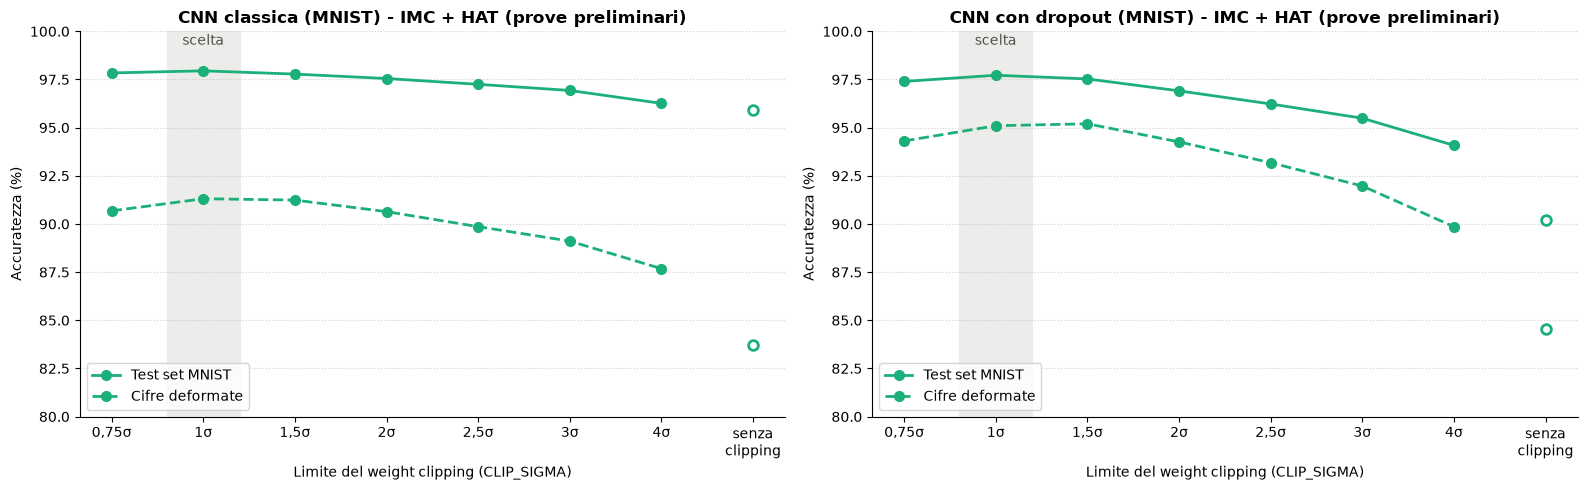

In [18]:
# Prove preliminari della tabella precedente: accuratezza dopo l'HAT al variare del limite del weight clipping
# (CLIP_SIGMA, in deviazioni standard), con 10 epoche. Ultimo punto: HAT senza clipping.
sigma_prove = [0.75, 1, 1.5, 2, 2.5, 3, 4]
prove_clipping = {   # per ogni rete: test set MNIST (%) per ogni valore di sigma_prove, senza clipping, poi lo stesso per le cifre deformate
    'CNN classica (MNIST)': ([97.84, 97.95, 97.78, 97.55, 97.25, 96.93, 96.26], 95.91,
                             [90.68, 91.31, 91.24, 90.64, 89.86, 89.11, 87.68], 83.70),
    'CNN con dropout (MNIST)': ([97.40, 97.72, 97.53, 96.91, 96.23, 95.49, 94.08], 90.21,
                                [94.31, 95.10, 95.20, 94.26, 93.18, 91.97, 89.86], 84.55),
}
x = np.arange(len(sigma_prove) + 1)   # posizioni sull'asse x: i valori di sigma, poi "senza clipping"
fig, axes = plt.subplots(1, 2, figsize=(16, 5), sharey=True)
for ax, (nome, (test, test_senza, deformate, deformate_senza)) in zip(axes, prove_clipping.items()):
    ax.axvspan(0.6, 1.4, color='#ececea', zorder=0)   # valore scelto: CLIP_SIGMA = 1
    ax.text(1, 99.3, 'scelta', ha='center', color=COLORE_TESTO)
    for valori, senza, etichetta, stile in [(test, test_senza, 'Test set MNIST', '-'),
                                            (deformate, deformate_senza, 'Cifre deformate', '--')]:
        ax.plot(x[:-1], valori, color=COLORE_HAT, linestyle=stile, linewidth=2, marker='o', markersize=7, label=etichetta)
        ax.plot(x[-1], senza, color=COLORE_HAT, marker='o', markersize=7, markerfacecolor='white', markeredgewidth=2)
    ax.set_xticks(x, [str(s).replace('.', ',') + 'σ' for s in sigma_prove] + ['senza\nclipping'])
    ax.set_xlabel('Limite del weight clipping (CLIP_SIGMA)')
    ax.set_ylim(80, 100)
    stile_grafico(ax, nome + ' - IMC + HAT (prove preliminari)')
    ax.yaxis.set_tick_params(labelleft=True)
    ax.legend(loc='lower left')
plt.tight_layout()
plt.savefig('grafici/hat_clipping_sigma.png', bbox_inches='tight', dpi=200)
plt.show()

In [19]:
# Weight clipping: limite dei pesi di ogni strato, in deviazioni standard dei pesi di partenza.
CLIP_SIGMA = 1

# Modified training wrapper for CrossSim-in-the-loop training
class SequentialWrapper_CrossSim(SequentialWrapper):
    def __init__(self, net, loss, learning_rate=1e-3, weight_decay=0.0, use_cosine_lr=False, limiti=None):
        super().__init__(net, loss, learning_rate, weight_decay, use_cosine_lr)
        # Limiti del weight clipping per ogni strato: calcolati dai pesi di partenza, oppure passati
        # (per continuare l'allenamento di una rete già riallenata con gli stessi limiti, sezione 8.2).
        if limiti is None:
            limiti = {nome: CLIP_SIGMA * p.detach().std().item()
                      for nome, p in net.named_parameters() if nome.endswith('weight')}
        self.limiti = limiti

    def training_step(self, batch, augmentation=None):
        loss = super().training_step(batch, augmentation)   # forward con errori IMC, backward e aggiornamento dei pesi
        with torch.no_grad():                               # weight clipping
            for nome, p in self.net.named_parameters():
                if nome in self.limiti:
                    p.clamp_(-self.limiti[nome], self.limiti[nome])
        synchronize(self.net)  # <--- riprogramma le RRAM con i nuovi pesi, con nuovi errori di programmazione
        return loss

# Architettura e file dei pesi dopo l'HAT di ogni rete.
architetture = {
    'CNN classica (MNIST)': mnist_cnn,
    'CNN con dropout (MNIST)': mnist_cnn_dropout,
    'CNN classica (MNIST + personale)': mnist_cnn,
    'CNN con dropout (MNIST + personale)': mnist_cnn_dropout,
}
file_hat = {
    'CNN classica (MNIST)': 'trained_mnist_cnn_hat.pt',
    'CNN con dropout (MNIST)': 'trained_mnist_cnn_dropout_hat.pt',
    'CNN classica (MNIST + personale)': 'trained_mnist_cnn_personale_hat.pt',
    'CNN con dropout (MNIST + personale)': 'trained_mnist_cnn_dropout_personale_hat.pt',
}

# Crea una rete con l'architettura indicata, ci carica i pesi e la converte su IMC (stessa configurazione della sezione 6).
def crea_rete_imc(nome, pesi):
    net = architetture[nome]()
    net.load_state_dict(pesi)
    return from_torch(net, params_imc)

# Seed fissi: l'HAT e i risultati delle sezioni successive non dipendono dalla parte provvisoria (7.1 e 7.2).
np.random.seed(0)
_ = torch.manual_seed(0)

# Reti IMC dopo l'HAT (moduli PyTorch con layer Cross-Sim), riempite nelle sezioni 8.1 e 8.2.
reti_hat = {}

### 8.1 HAT delle reti allenate su MNIST

Le due reti del notebook (1) vengono riallenate su MNIST con gli errori dell'IMC, ognuna con le **stesse impostazioni** del notebook (1):
- **CNN classica**: ottimizzatore Adam, senza data augmentation;
- **CNN con dropout**: AdamW con weight decay, data augmentation (sezione 4.1) e Dropout attivo durante il training.

Per entrambe si usano 10 epoche, con learning rate che parte da $10^{-3}$ e scende verso 0 (cosine annealing): passi ampi all'inizio, per spostare i pesi verso valori robusti agli errori, e passi piccoli alla fine per rifinirli. Per entrambe è attivo il weight clipping.

A ogni epoca la validation loss viene calcolata sulla rete IMC (con gli errori), sulle immagini di validazione che le reti non hanno mai usato per allenarsi.

In [20]:
# Number of training epochs
N_epochs_hat = 10

# Impostazioni del notebook (1) per ognuna delle due reti: (weight decay, data augmentation)
impostazioni_hat = {
    'CNN classica (MNIST)': (0.0, None),
    'CNN con dropout (MNIST)': (1e-4, augment_batch),
}

loss_hat, limiti_hat = {}, {}
for nome, (weight_decay, augmentation) in impostazioni_hat.items():
    # Create a PyTorch model with CrossSim-compatible layers, partendo dai pesi già allenati (sezione 5)
    imc_net = crea_rete_imc(nome, reti[nome].net.state_dict())
    # Create the wrapped analog PyTorch model
    imc_net_CS = SequentialWrapper_CrossSim(imc_net, torch.nn.CrossEntropyLoss(), learning_rate=1e-3,
                                            weight_decay=weight_decay, use_cosine_lr=True)
    # Train the analog PyTorch model
    print(nome)
    loss_hat[nome] = imc_net_CS.train(mnist_loader_train, mnist_loader_val, N_epochs_hat, augmentation=augmentation)
    limiti_hat[nome] = imc_net_CS.limiti    # limiti del weight clipping, riusati nella sezione 8.2
    # Quota di pesi che alla fine si trovano al limite del weight clipping
    pesi = [(p, imc_net_CS.limiti[n]) for n, p in imc_net.named_parameters() if n in imc_net_CS.limiti]
    al_limite = sum((p.abs() >= limite * 0.999).sum().item() for p, limite in pesi)
    print('Pesi al limite del weight clipping: {:.0f}%'.format(100 * al_limite / sum(p.numel() for p, _ in pesi)))
    # Save the model
    torch.save(imc_net.state_dict(), file_hat[nome])
    reti_hat[nome] = imc_net

CNN classica (MNIST)


  0%|          | 0/10 [00:00<?, ?it/s]

 10%|█         | 1/10 [00:12<01:48, 12.03s/it]

 20%|██        | 2/10 [00:24<01:37, 12.16s/it]

 30%|███       | 3/10 [00:36<01:25, 12.17s/it]

 40%|████      | 4/10 [00:48<01:12, 12.16s/it]

... (17 outputs left out)

 90%|█████████ | 9/10 [02:27<00:17, 17.25s/it]

100%|██████████| 10/10 [02:44<00:00, 17.23s/it]

100%|██████████| 10/10 [02:44<00:00, 16.45s/it]

Pesi al limite del weight clipping: 7%


Rappresentiamo le curve di training e validation loss dell'HAT. Le reti partono da pesi già allenati, quindi le loss sono basse già dalla prima epoca; entrambe sono calcolate sulla rete IMC, cioè con gli errori di programmazione. Come nel notebook (1), per la rete con dropout la training loss è più alta della validation loss, perché dropout e data augmentation agiscono solo durante il training.

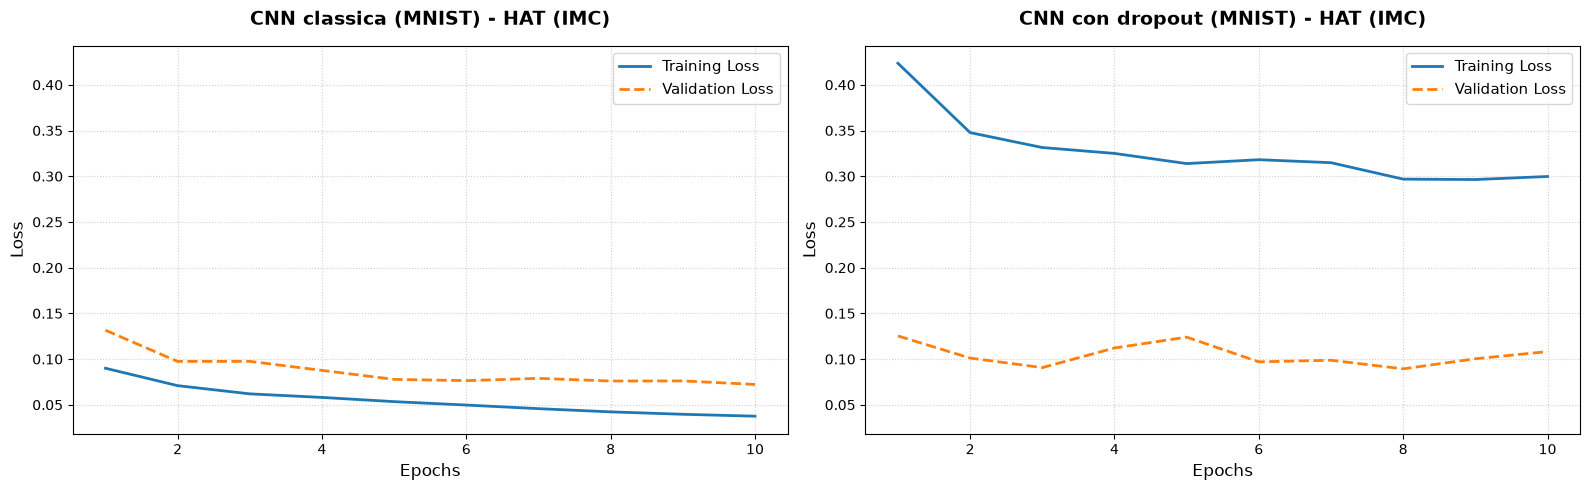

In [21]:
# Curve di training e validation loss dell'HAT delle due reti MNIST, salvate in train_val_loss_hat.png
def plot_losses(ax, loss_train, loss_val, title):
    x_axis_epochs = np.arange(1, len(loss_train) + 1)
    ax.plot(x_axis_epochs, loss_train, label='Training Loss', color='#1f77b4', linewidth=2)
    ax.plot(x_axis_epochs, loss_val, label='Validation Loss', color='#ff7f0e', linewidth=2, linestyle='--')
    ax.set_title(title, fontsize=14, fontweight='bold', pad=15)
    ax.set_xlabel('Epochs', fontsize=12)
    ax.set_ylabel('Loss', fontsize=12)
    ax.grid(True, linestyle=':', alpha=0.6)
    ax.legend(fontsize=11)

fig, axes = plt.subplots(1, 2, figsize=(16, 5), sharey=True)
for ax, nome in zip(axes, impostazioni_hat):
    plot_losses(ax, *loss_hat[nome], nome + ' - HAT (IMC)')
axes[1].yaxis.set_tick_params(labelleft=True)
plt.tight_layout()
plt.savefig('train_val_loss_hat.png', bbox_inches='tight', dpi=200)
plt.show()

Per vedere l'effetto dell'HAT e del weight clipping sui pesi, confrontiamo la distribuzione dei pesi di ogni strato prima dell'HAT (rete digitale) e dopo l'HAT, con i limiti del weight clipping (linee tratteggiate). L'asse y è in scala logaritmica, così si vedono anche i pochi pesi fuori scala: nella rete con dropout, prima dell'HAT, alcuni pesi sono molto lontani dagli altri (sezione 7); dopo l'HAT tutti i pesi stanno dentro i limiti.

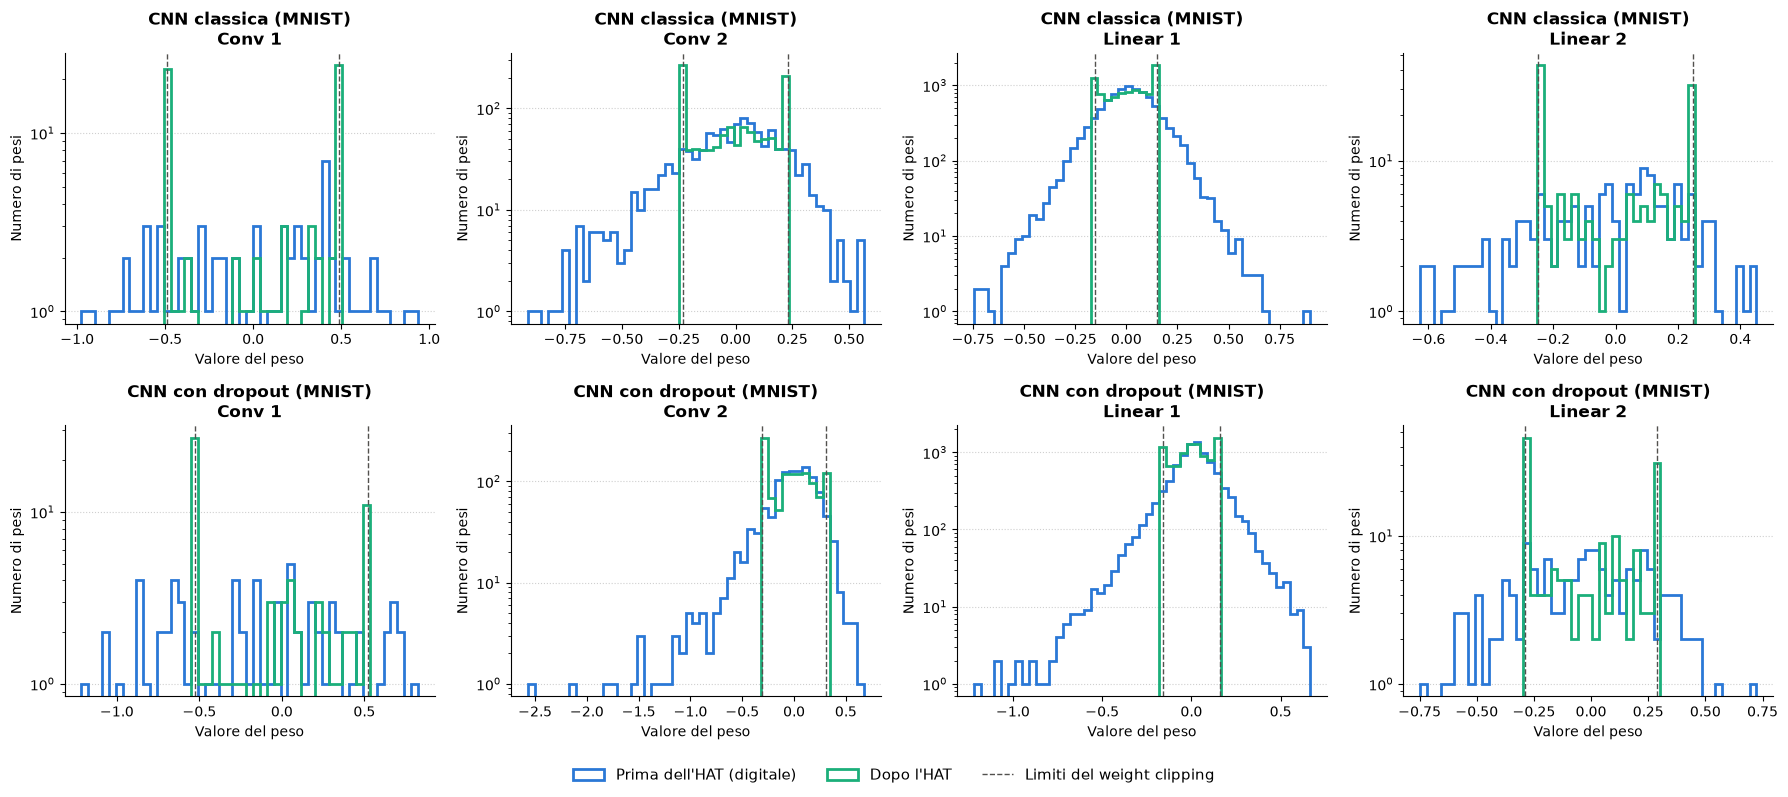

In [22]:
# Distribuzione dei pesi di ogni strato prima e dopo l'HAT, con i limiti del weight clipping.
nomi_strati = ['Conv 1', 'Conv 2', 'Linear 1', 'Linear 2']
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for riga, nome in zip(axes, impostazioni_hat):
    pesi_prima = [(n, p) for n, p in reti[nome].net.named_parameters() if n.endswith('weight')]
    pesi_dopo = dict(reti_hat[nome].named_parameters())
    for ax, nome_strato, (n, p) in zip(riga, nomi_strati, pesi_prima):
        prima = p.detach().flatten().numpy()
        dopo = pesi_dopo[n].detach().flatten().numpy()
        bins = np.linspace(min(prima.min(), dopo.min()), max(prima.max(), dopo.max()), 50)
        ax.hist(prima, bins=bins, histtype='step', linewidth=2, color=COLORE_DIGITALE, label="Prima dell'HAT (digitale)")
        ax.hist(dopo, bins=bins, histtype='step', linewidth=2, color=COLORE_HAT, label="Dopo l'HAT")
        for segno in (-1, 1):
            ax.axvline(segno * limiti_hat[nome][n], color=COLORE_TESTO, linestyle='--', linewidth=1,
                       label='Limiti del weight clipping' if segno == 1 else None)
        ax.set_yscale('log')
        ax.set_xlabel('Valore del peso')
        stile_grafico(ax, '{}\n{}'.format(nome, nome_strato), ylabel='Numero di pesi')
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', ncol=3, frameon=False, fontsize=11)
plt.tight_layout(rect=(0, 0.05, 1, 1))
plt.savefig('grafici/hat_distribuzione_pesi.png', bbox_inches='tight', dpi=200)
plt.show()

### 8.2 HAT delle reti allenate anche sul dataset personale

Nel notebook (2) le reti "MNIST + personale" sono state ottenute dalle reti MNIST con un allenamento aggiuntivo sul dataset personale. Per l'HAT seguiamo lo **stesso percorso**, ma con gli errori dell'IMC in ogni passo:
1. si parte dalle reti MNIST dopo l'HAT (sezione 8.1);
2. si allenano sul dataset personale con le stesse impostazioni del notebook (2): tutti i disegni, 30 epoche, learning rate $3 \cdot 10^{-4}$, data augmentation e mini-batch di 16 disegni, ma con il Wrapper Cross-Sim (e gli stessi limiti del weight clipping della rete MNIST di partenza).

Così le reti imparano la nostra grafia e restano robuste agli errori dell'IMC.

In [23]:
# Allenamento sul dataset personale con gli errori dell'IMC (stesse impostazioni della sezione 8 del notebook 2).
EPOCHE_PERSONALE = 30     # poche epoche: le reti sanno già riconoscere le cifre
LR_PERSONALE = 3e-4       # learning rate più basso di quello usato su MNIST (1e-3)

# Dataset personale preparato come nel notebook (2): cambia solo la scala dei pixel, i disegni non vengono adattati a MNIST.
data = torch.load('dataset_personale.pt')
x_pers = data['images'].float().unsqueeze(1) / 255.0                  # (N, 1, 28, 28), valori 0-1
x_pers = (x_pers - 0.1307) / 0.3081                                     # stessa normalizzazione di MNIST
y_pers = F.one_hot(data['labels'], 10).float()                         # etichette one-hot
pers_loader = torch.utils.data.DataLoader(torch.utils.data.TensorDataset(x_pers, y_pers), batch_size=16, shuffle=True)

for nome, nome_mnist in [('CNN classica (MNIST + personale)', 'CNN classica (MNIST)'),
                         ('CNN con dropout (MNIST + personale)', 'CNN con dropout (MNIST)')]:
    # Copia della rete MNIST dopo l'HAT (sezione 8.1), che resta invariata
    imc_net = crea_rete_imc(nome, reti_hat[nome_mnist].state_dict())
    # Stessi limiti del weight clipping della rete MNIST di partenza
    imc_net_CS = SequentialWrapper_CrossSim(imc_net, torch.nn.CrossEntropyLoss(), learning_rate=LR_PERSONALE,
                                            limiti=limiti_hat[nome_mnist])
    print(nome)
    imc_net.train()                                 # Dropout attivo durante l'allenamento
    for _ in tqdm(range(EPOCHE_PERSONALE)):
        for inputs, labels in pers_loader:
            imc_net_CS.training_step((inputs, labels), augment_batch)
    imc_net.eval()                                  # di nuovo in modalità inferenza
    torch.save(imc_net.state_dict(), file_hat[nome])
    reti_hat[nome] = imc_net

# Stesso ordine delle reti della sezione 5
reti_hat = {nome: reti_hat[nome] for nome in reti}

CNN classica (MNIST + personale)


  0%|          | 0/30 [00:00<?, ?it/s]

  7%|▋         | 2/30 [00:00<00:01, 18.21it/s]

 17%|█▋        | 5/30 [00:00<00:01, 20.46it/s]

 27%|██▋       | 8/30 [00:00<00:01, 20.26it/s]

 37%|███▋      | 11/30 [00:00<00:00, 20.32it/s]

... (16 outputs left out)

 80%|████████  | 24/30 [00:01<00:00, 20.44it/s]

 90%|█████████ | 27/30 [00:01<00:00, 20.67it/s]

100%|██████████| 30/30 [00:01<00:00, 20.69it/s]

100%|██████████| 30/30 [00:01<00:00, 20.54it/s]

## 9. Verifica dell'accuratezza dopo l'HAT

Ripetiamo sulle 4 reti riallenate lo stesso test della sezione 7: inferenza sull'intero test set, ripetuta su `N_runs` chip simulati con errori di programmazione ricampionati. I chip sono nuovi, diversi da quelli usati durante il training, quindi il risultato misura quanto la rete funziona su un chip qualsiasi.

In [24]:
# Perform analog inference on the test set
accuracy_hat, accuracy_hat_chip = {}, {}
for nome, imc_net in reti_hat.items():
    risultati = valuta_imc(imc_net, lambda net: accuracy(net, mnist_loader_test), N_runs, nome + ' - IMC + HAT')
    accuracy_hat_chip[nome] = risultati
    accuracy_hat[nome] = (np.mean(risultati), np.std(risultati))

# Evaluate average test accuracy
stampa_tabella('CrossSim analog errors during training, CrossSim analog errors during test',
               ['Digitale', 'IMC', 'IMC + HAT'],
               [(nome, [valore(*accuracy_digitale[nome]), valore(*accuracy_imc[nome]), valore(*accuracy_hat[nome])])
                for nome in reti])


CrossSim analog errors during training, CrossSim analog errors during test
Rete                                                            Digitale                 IMC           IMC + HAT
CNN classica (MNIST)                                              98.04%      82.84% ± 4.46%      97.95% ± 0.17%
CNN con dropout (MNIST)                                           98.59%      44.90% ± 8.40%      97.74% ± 0.24%
CNN classica (MNIST + personale)                                  96.25%      74.99% ± 5.51%      96.11% ± 0.57%
CNN con dropout (MNIST + personale)                               96.76%      42.18% ± 9.04%      95.95% ± 0.63%


Il grafico mostra l'accuratezza di **ogni singolo chip** simulato: per ogni rete, a sinistra i chip senza HAT (sezione 7) e a destra i chip dopo l'HAT; la linea blu è l'accuratezza della stessa rete digitale. Senza HAT i risultati cambiano molto da un chip all'altro, soprattutto per le reti con dropout; dopo l'HAT tutti i chip si raccolgono vicino all'accuratezza digitale.

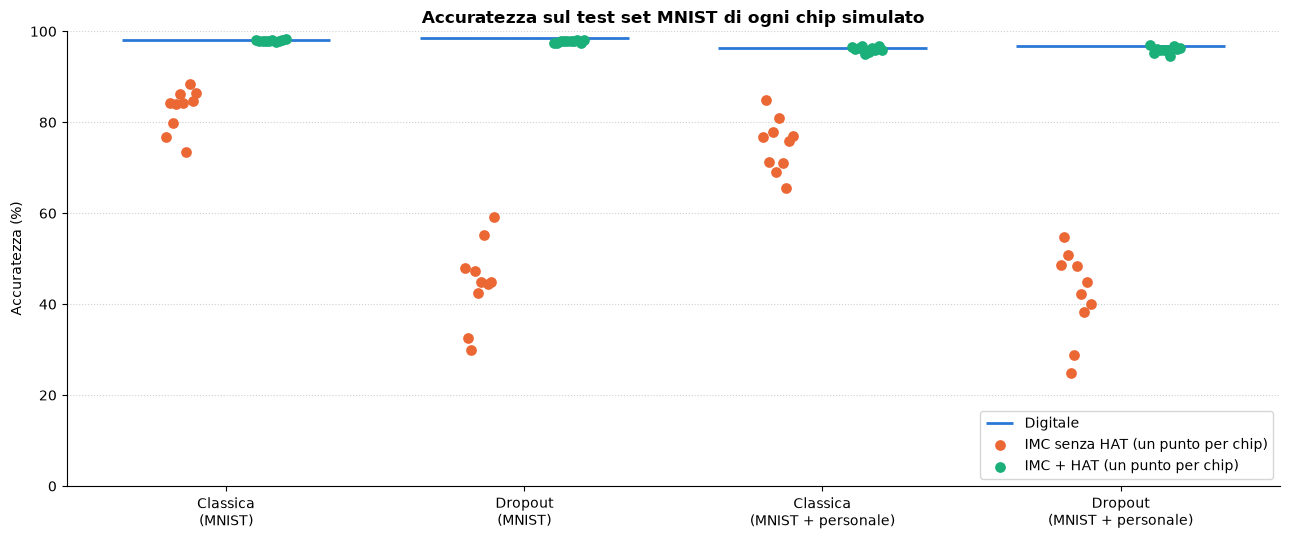

In [25]:
# Accuratezza di ogni chip simulato: IMC senza HAT (sezione 7) e IMC dopo l'HAT, con la rete digitale come riferimento.
fig, ax = plt.subplots(figsize=(13, 5.5))
scarto = np.linspace(-0.05, 0.05, N_runs)   # piccolo spostamento orizzontale per non sovrapporre i punti
for i, nome in enumerate(reti):
    ax.hlines(100*accuracy_digitale[nome][0], i - 0.35, i + 0.35, color=COLORE_DIGITALE, linewidth=2,
              label='Digitale' if i == 0 else None)
    ax.scatter(i - 0.15 + scarto, 100*accuracy_imc_chip[nome], color=COLORE_IMC, s=45, zorder=3,
               label='IMC senza HAT (un punto per chip)' if i == 0 else None)
    ax.scatter(i + 0.15 + scarto, 100*accuracy_hat_chip[nome], color=COLORE_HAT, s=45, zorder=3,
               label='IMC + HAT (un punto per chip)' if i == 0 else None)
ax.set_xticks(range(len(reti)), [NOMI_BREVI[nome] for nome in reti])
ax.set_ylim(0, 100)
stile_grafico(ax, 'Accuratezza sul test set MNIST di ogni chip simulato')
ax.legend(loc='lower right')
plt.tight_layout()
plt.savefig('grafici/accuratezza_per_chip.png', bbox_inches='tight', dpi=200)
plt.show()

## 10. Robustezza dopo l'HAT

Ripetiamo sulle 4 reti IMC dopo l'HAT i test di robustezza della sezione 5.1 (cifre deformate e disegni della lavagna), con `N_runs` chip simulati per rete. Ogni rete è affiancata dalla stessa rete digitale, cioè prima dell'HAT e senza errori (sezione 5.1). Con 4 disegni per cifra ogni disegno vale il 2,5% del totale, quindi i valori sulla lavagna vanno letti come indicativi.

In [26]:
# Robustezza delle 4 reti IMC dopo l'HAT (funzioni della sezione 4.1), media su N_runs chip.
for nome, imc_net in reti_hat.items():
    nome_hat = nome + ' - IMC + HAT'
    deformate = valuta_imc(imc_net, lambda net: accuracy_deformed(net, mnist_loader_test), N_runs, nome_hat + ' (cifre deformate)')
    robustezza_deformate[nome_hat] = (np.mean(deformate), np.std(deformate))
    corretti = valuta_imc(imc_net, corretti_lavagna, N_runs, nome_hat + ' (lavagna)')   # (N_runs, 10)
    corretti_per_cifra[nome_hat] = corretti.mean(axis=0)
    totali = corretti.sum(axis=1) / len(y_lavagna)
    robustezza_lavagna[nome_hat] = (np.mean(totali), np.std(totali))

righe = []
for nome in reti:
    righe.append((nome, [valore(*accuracy_digitale[nome]), valore(*robustezza_deformate[nome]), valore(*robustezza_lavagna[nome])]))
    righe.append((nome + ' - IMC + HAT', [valore(*accuracy_hat[nome]), valore(*robustezza_deformate[nome + ' - IMC + HAT']),
                                          valore(*robustezza_lavagna[nome + ' - IMC + HAT'])]))
stampa_tabella('Robustezza dopo l\'HAT', ['Test accuracy', 'Cifre deformate', 'Lavagna'], righe)
print()
stampa_per_cifra('Disegni riconosciuti per cifra', [n for nome in reti for n in (nome, nome + ' - IMC + HAT')])


CNN classica (MNIST) - IMC + HAT (lavagna): inference simulation 10 of 10



CNN con dropout (MNIST) - IMC + HAT (lavagna): inference simulation 10 of 10



CNN classica (MNIST + personale) - IMC + HAT (lavagna): inference simulation 10 of 10



CNN con dropout (MNIST + personale) - IMC + HAT (lavagna): inference simulation 10 of 10
Robustezza dopo l'HAT
Rete                                                       Test accuracy     Cifre deformate             Lavagna
CNN classica (MNIST)                                              98.04%              92.53%              85.00%
CNN classica (MNIST) - IMC + HAT                          97.95% ± 0.17%      91.48% ± 0.35%      88.50% ± 5.02%
CNN con dropout (MNIST)                                           98.59%              97.30%              85.00%
CNN con dropout (MNIST) - IMC + HAT                       97.74% ± 0.24%      95.20% ± 0.40%              85.00%
CNN classica (MNIST + personale)                                  96.25%              88.22%             100.00%
CNN classica (MNIST + personale) - IMC + HAT              96.11% ± 0.57%      87.83% ± 1.07%      96.00% ± 4.36%
CNN con dropout (MNIST + personale)                               96.76%              95.03%     

### 10.1 Robustezza al crescere della rotazione

I test precedenti danno un solo valore di robustezza. Per vedere l'**andamento**, ruotiamo tutte le cifre del test set dello stesso angolo (da 0° a 50°, metà in senso orario e metà antiorario, funzione `accuracy_rotated` della sezione 4.1) e misuriamo l'accuratezza della rete digitale e della rete IMC dopo l'HAT. Per le reti IMC ogni punto è la media su `N_runs_rotazione` chip (meno di `N_runs`, per contenere i tempi), con una fascia di ± una deviazione standard.


Accuratezza (%) al crescere della rotazione
Rete                                                             0 gradi            10 gradi            20 gradi            30 gradi            40 gradi            50 gradi
CNN classica (MNIST)                                                98.0                97.1                90.9                76.8                55.6                36.0
CNN classica (MNIST) - IMC + HAT                                    97.9                96.6                90.2                76.0                54.4                35.4
CNN con dropout (MNIST)                                             98.6                98.5                96.3                88.2                71.2                48.8
CNN con dropout (MNIST) - IMC + HAT                                 97.6                97.1                93.7                84.0                65.5                42.4
CNN classica (MNIST + personale)                                    96.2                93

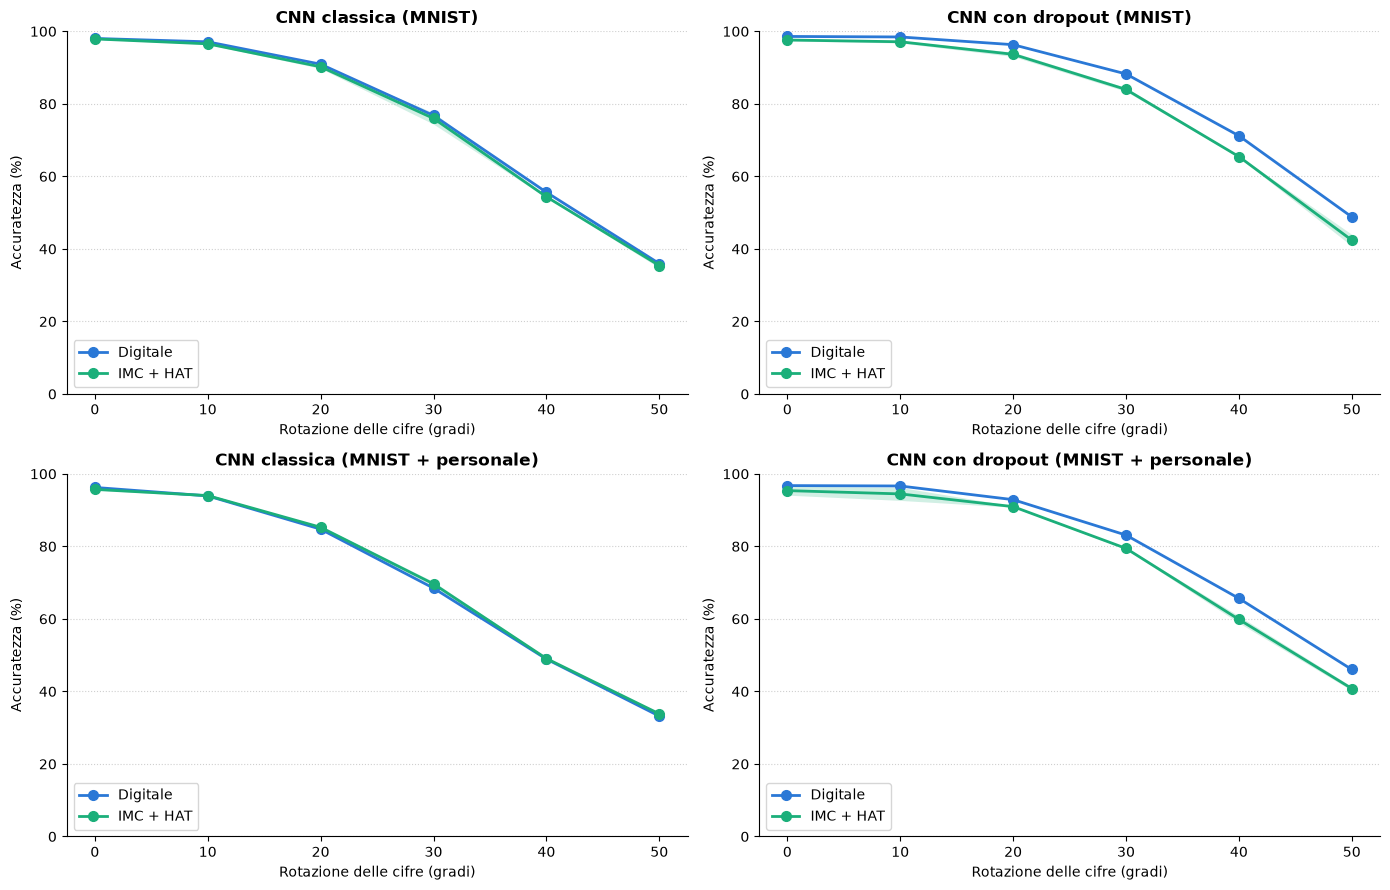

In [27]:
# Accuratezza al crescere della rotazione delle cifre: rete digitale e rete IMC dopo l'HAT.
ANGOLI = [0, 10, 20, 30, 40, 50]   # gradi
N_runs_rotazione = 3               # chip simulati per ogni punto delle reti IMC

rotazione_digitale, rotazione_hat = {}, {}
for nome in reti:
    rotazione_digitale[nome] = np.array([accuracy_rotated(reti[nome].net, mnist_loader_test, g) for g in ANGOLI])
    rotazione_hat[nome] = np.array([valuta_imc(reti_hat[nome], lambda net: accuracy_rotated(net, mnist_loader_test, g),
                                               N_runs_rotazione, '{} - IMC + HAT, rotazione {} gradi'.format(nome, g))
                                    for g in ANGOLI])   # una riga per angolo, una colonna per chip

# Tabella con gli stessi valori del grafico (per le reti IMC la media sui chip)
stampa_tabella('Accuratezza (%) al crescere della rotazione', ['{} gradi'.format(g) for g in ANGOLI],
               [(n, ['{:.1f}'.format(100*a) for a in acc]) for nome in reti
                for n, acc in ((nome, rotazione_digitale[nome]), (nome + ' - IMC + HAT', rotazione_hat[nome].mean(axis=1)))])

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for ax, nome in zip(axes.flat, reti):
    media, std = 100*rotazione_hat[nome].mean(axis=1), 100*rotazione_hat[nome].std(axis=1)
    ax.plot(ANGOLI, 100*rotazione_digitale[nome], color=COLORE_DIGITALE, linewidth=2, marker='o', markersize=7, label='Digitale')
    ax.plot(ANGOLI, media, color=COLORE_HAT, linewidth=2, marker='o', markersize=7, label='IMC + HAT')
    ax.fill_between(ANGOLI, media - std, media + std, color=COLORE_HAT, alpha=0.2, linewidth=0)
    ax.set_ylim(0, 100)
    ax.set_xticks(ANGOLI)
    ax.set_xlabel('Rotazione delle cifre (gradi)')
    stile_grafico(ax, nome)
    ax.legend(loc='lower left')
plt.tight_layout()
plt.savefig('grafici/robustezza_rotazione.png', bbox_inches='tight', dpi=200)
plt.show()

## 11. Inferenza Live con la lavagna: reti digitali e reti IMC dopo l'HAT

Apriamo la lavagna con 8 reti: le 4 reti digitali (sezione 5) e le 4 reti IMC dopo l'HAT (sezione 8). Disegnando una cifra, il grafico mostra affiancate le percentuali della Softmax di ogni rete, così si vede se le reti IMC riallenate riconoscono la cifra con la stessa sicurezza delle reti digitali, e quali reti riconoscono meglio la nostra grafia.

- Come in tutte le lavagne, il disegno viene solo rimpicciolito a 28x28, senza adattarlo a MNIST.
- Ogni rete IMC sulla lavagna corrisponde a un solo chip simulato: quello estratto dall'ultimo `reinitialize` della sezione 10. Rieseguendo le sezioni 9 e 10 il chip cambia, quindi anche le risposte della lavagna possono cambiare.

La cella resta in esecuzione finché la finestra è aperta: chiudila per continuare a usare il notebook.

In [ ]:
# 4 reti digitali + le 4 reti IMC dopo l'HAT (dizionario reti_hat della sezione 8).
apri_lavagna({**reti, **{nome + ' - IMC + HAT': imc_net for nome, imc_net in reti_hat.items()}})

## 12. Summary Table

Riepilogo di tutti i risultati delle 4 reti:
- **Digitale**: standard training, standard inference (sezione 5);
- **IMC**: standard training, CrossSim inference (sezione 7);
- **IMC + HAT**: CrossSim training, CrossSim inference (sezioni 8 e 9).

Per le reti IMC i valori sono media e deviazione standard su `N_runs` chip simulati.

In [29]:
stampa_tabella('Accuracy on MNIST test set', ['Digitale', 'IMC', 'IMC + HAT'],
               [(nome, [valore(*accuracy_digitale[nome]), valore(*accuracy_imc[nome]), valore(*accuracy_hat[nome])])
                for nome in reti])
print()
stampa_tabella('Robustezza: cifre deformate e disegni della lavagna',
               ['Deformate digitale', 'Deformate IMC+HAT', 'Lavagna digitale', 'Lavagna IMC+HAT'],
               [(nome, [valore(*robustezza_deformate[nome]), valore(*robustezza_deformate[nome + ' - IMC + HAT']),
                        valore(*robustezza_lavagna[nome]), valore(*robustezza_lavagna[nome + ' - IMC + HAT'])])
                for nome in reti])

Accuracy on MNIST test set
Rete                                                            Digitale                 IMC           IMC + HAT
CNN classica (MNIST)                                              98.04%      82.84% ± 4.46%      97.95% ± 0.17%
CNN con dropout (MNIST)                                           98.59%      44.90% ± 8.40%      97.74% ± 0.24%
CNN classica (MNIST + personale)                                  96.25%      74.99% ± 5.51%      96.11% ± 0.57%
CNN con dropout (MNIST + personale)                               96.76%      42.18% ± 9.04%      95.95% ± 0.63%

Robustezza: cifre deformate e disegni della lavagna
Rete                                                  Deformate digitale   Deformate IMC+HAT    Lavagna digitale     Lavagna IMC+HAT
CNN classica (MNIST)                                              92.53%      91.48% ± 0.35%              85.00%      88.50% ± 5.02%
CNN con dropout (MNIST)                                           97.30%      95.20% ± 0.

### Grafici riassuntivi

Gli stessi risultati delle tabelle in forma grafica: a sinistra l'accuratezza sul test set MNIST (digitale, IMC senza HAT, IMC dopo l'HAT), al centro e a destra la robustezza (cifre deformate e disegni della lavagna) della rete digitale e della rete IMC dopo l'HAT. Per le reti IMC le barre di errore sono la deviazione standard sui chip simulati.

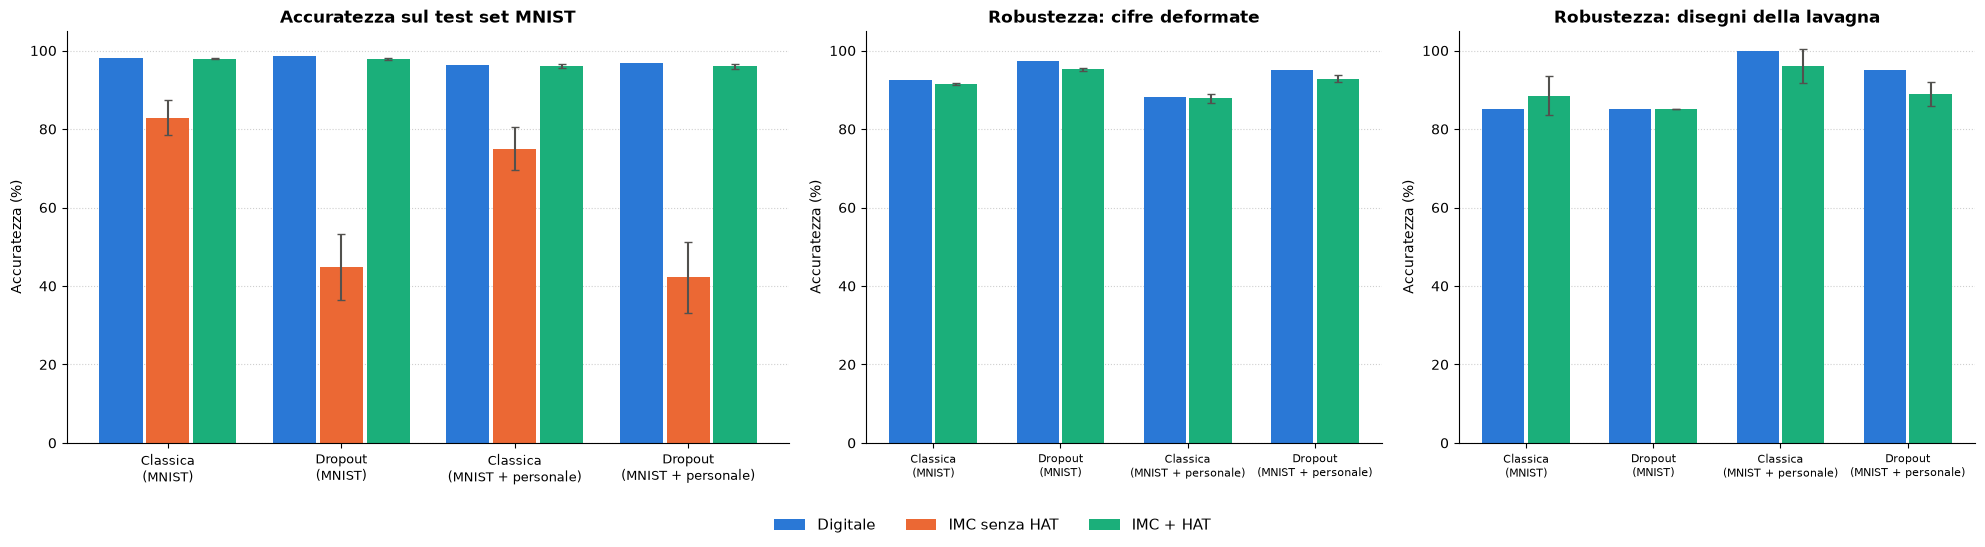

In [30]:
# Grafici riassuntivi: accuratezza e robustezza delle 4 reti.
x = np.arange(len(reti))
etichette = [NOMI_BREVI[nome] for nome in reti]

# Una barra per serie e per rete. serie: lista di (etichetta, {nome: (media, std)}, colore).
def barre(ax, serie, larghezza):
    for k, (etichetta, dati, colore) in enumerate(serie):
        spostamento = (k - (len(serie) - 1) / 2) * larghezza
        std = [100*dati[n][1] for n in reti]
        ax.bar(x + spostamento, [100*dati[n][0] for n in reti], larghezza * 0.92,
               yerr=std if any(std) else None,   # le reti digitali non hanno barre di errore
               capsize=3, color=colore, ecolor=COLORE_TESTO, label=etichetta)
    ax.set_xticks(x, etichette)
    ax.set_ylim(0, 105)

fig, axes = plt.subplots(1, 3, figsize=(20, 5.5), gridspec_kw={'width_ratios': [1.4, 1, 1]})
barre(axes[0], [('Digitale', accuracy_digitale, COLORE_DIGITALE), ('IMC senza HAT', accuracy_imc, COLORE_IMC),
                ('IMC + HAT', accuracy_hat, COLORE_HAT)], 0.27)
stile_grafico(axes[0], 'Accuratezza sul test set MNIST')
axes[0].tick_params(axis='x', labelsize=9)
for ax, titolo, dati in [(axes[1], 'Robustezza: cifre deformate', robustezza_deformate),
                         (axes[2], 'Robustezza: disegni della lavagna', robustezza_lavagna)]:
    barre(ax, [('Digitale', {n: dati[n] for n in reti}, COLORE_DIGITALE),
               ('IMC + HAT', {n: dati[n + ' - IMC + HAT'] for n in reti}, COLORE_HAT)], 0.36)
    stile_grafico(ax, titolo)
    ax.tick_params(axis='x', labelsize=8)
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', ncol=3, frameon=False, fontsize=11)
plt.tight_layout(rect=(0, 0.08, 1, 1))
plt.savefig('grafici/riepilogo.png', bbox_inches='tight', dpi=200)
plt.show()